In [5]:
# Step 1: Import libraries and load the dataset
import pandas as pd

# Load Excel file
file_path = "Turbine_Data 2.xlsx"  # Update with correct path if needed
xls = pd.ExcelFile('/Users/yashwanth/Library/Mobile Documents/com~apple~Numbers/Documents/Turbine_Data 2.xlsx')

# View available sheet names (optional)
print(xls.sheet_names)

# Load the relevant sheet (assumed to be 'Sheet 1 - Turbine_Data')
df = xls.parse('Sheet 1 - Turbine_Data')

# Rename the first column to 'Timestamp' and convert to datetime
df.rename(columns={df.columns[0]: 'Timestamp'}, inplace=True)
df['Timestamp'] = pd.to_datetime(df['Timestamp'])

# Display basic info about dataset
print(df.info())

# Check for missing values
missing_values = df.isnull().sum()
missing_values = missing_values[missing_values > 0].sort_values(ascending=False)
print("Missing values:\n", missing_values)

['Sheet 1 - Turbine_Data']
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 118224 entries, 0 to 118223
Data columns (total 22 columns):
 #   Column                        Non-Null Count   Dtype              
---  ------                        --------------   -----              
 0   Timestamp                     118224 non-null  datetime64[ns, UTC]
 1   ActivePower                   94750 non-null   float64            
 2   AmbientTemperatue             93817 non-null   float64            
 3   BearingShaftTemperature       62518 non-null   float64            
 4   Blade1PitchAngle              41996 non-null   float64            
 5   Blade2PitchAngle              41891 non-null   float64            
 6   Blade3PitchAngle              41891 non-null   float64            
 7   ControlBoxTemperature         62160 non-null   float64            
 8   GearboxBearingTemperature     62540 non-null   float64            
 9   GearboxOilTemperature         62438 non-null   float64           

In [6]:
# Create a copy of the original DataFrame
df_imputed = df.copy()

# Apply forward fill first, then backward fill for any remaining missing values
df_imputed.fillna(method='ffill', inplace=True)
df_imputed.fillna(method='bfill', inplace=True)

# Optional: Verify there are no missing values left
print(df_imputed.isnull().sum())

Timestamp                       0
ActivePower                     0
AmbientTemperatue               0
BearingShaftTemperature         0
Blade1PitchAngle                0
Blade2PitchAngle                0
Blade3PitchAngle                0
ControlBoxTemperature           0
GearboxBearingTemperature       0
GearboxOilTemperature           0
GeneratorRPM                    0
GeneratorWinding1Temperature    0
GeneratorWinding2Temperature    0
HubTemperature                  0
MainBoxTemperature              0
NacellePosition                 0
ReactivePower                   0
RotorRPM                        0
TurbineStatus                   0
WTG                             0
WindDirection                   0
WindSpeed                       0
dtype: int64


/var/folders/_y/r_y25lcd4ysdnk8f0xjyzm0h0000gn/T/ipykernel_1614/2654584931.py:5: FutureWarning: DataFrame.fillna with 'method' is deprecated and will raise in a future version. Use obj.ffill() or obj.bfill() instead.
  df_imputed.fillna(method='ffill', inplace=True)
/var/folders/_y/r_y25lcd4ysdnk8f0xjyzm0h0000gn/T/ipykernel_1614/2654584931.py:6: FutureWarning: DataFrame.fillna with 'method' is deprecated and will raise in a future version. Use obj.ffill() or obj.bfill() instead.
  df_imputed.fillna(method='bfill', inplace=True)


In [9]:
# Step 3: Outlier detection and removal using IQR

def remove_outliers_iqr(df, column):
    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)
    IQR = Q3 - Q1
    lower_limit = Q1 - 1.5 * IQR
    upper_limit = Q3 + 1.5 * IQR
    df_clean = df[(df[column] >= lower_limit) & (df[column] <= upper_limit)]
    return df_clean

# Apply to key numerical columns one by one
for col in ['WindSpeed', 'RotorRPM', 'ActivePower']:
    df_imputed = remove_outliers_iqr(df_imputed, col)

# Check the shape after removing outliers
print("Shape after outlier removal:", df_imputed.shape)

Shape after outlier removal: (116652, 22)


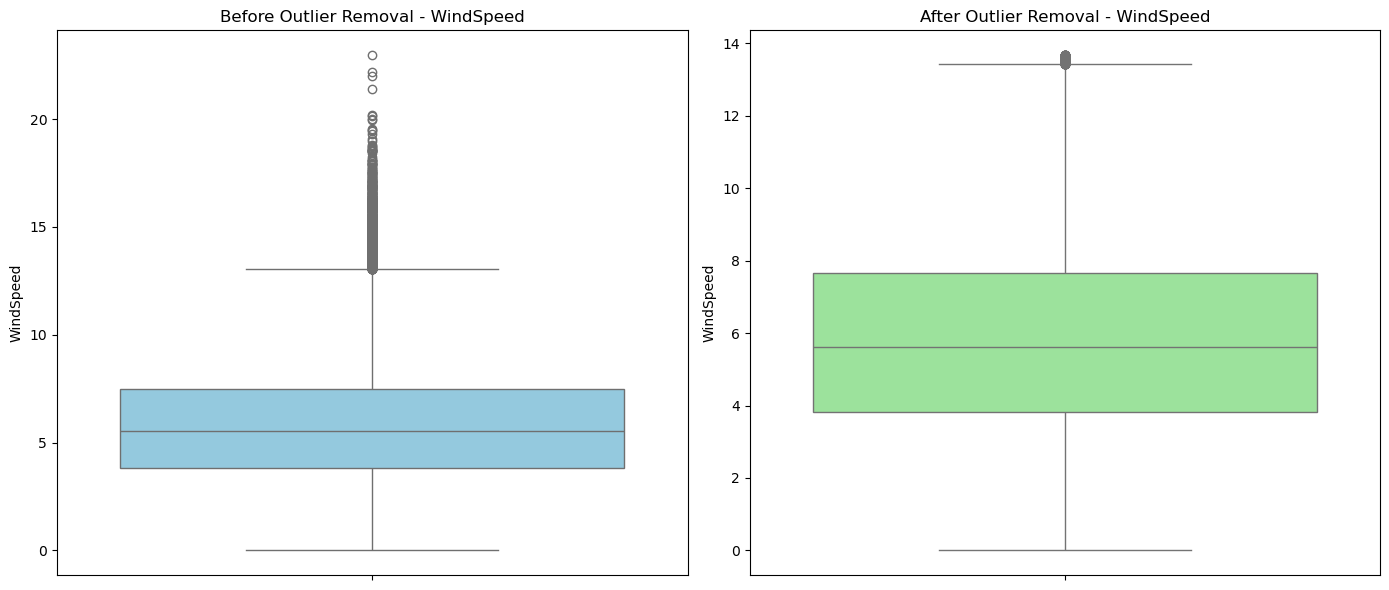

In [11]:
import matplotlib.pyplot as plt
import seaborn as sns

# Side-by-side boxplots for 'WindSpeed'
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Before removal
sns.boxplot(y=df['WindSpeed'], ax=axes[0], color='skyblue')
axes[0].set_title('Before Outlier Removal - WindSpeed')

# After removal
sns.boxplot(y=df_imputed['WindSpeed'], ax=axes[1], color='lightgreen')
axes[1].set_title('After Outlier Removal - WindSpeed')

plt.tight_layout()
plt.show()

In [13]:
from sklearn.preprocessing import StandardScaler

# Copy dataset
df_scaled = df_imputed.copy()

# Drop 'Timestamp' and any non-numeric columns like 'Turbine_ID'
numeric_cols = df_scaled.select_dtypes(include=['float64', 'int64']).columns
features_to_scale = df_scaled[numeric_cols]

# Scale the numeric features
scaler = StandardScaler()
scaled_array = scaler.fit_transform(features_to_scale)

# Rebuild scaled DataFrame
scaled_df = pd.DataFrame(scaled_array, columns=numeric_cols)
scaled_df['Timestamp'] = df_imputed['Timestamp'].values  # Add timestamp back

# Show scaled data
print(scaled_df.head())


   ActivePower  AmbientTemperatue  BearingShaftTemperature  Blade1PitchAngle  \
0    -1.025085          -1.254168                 0.461596           0.62934   
1    -1.025085          -1.254168                 0.461596           0.62934   
2    -1.025085          -1.254168                 0.461596           0.62934   
3    -1.025085          -1.254168                 0.461596           0.62934   
4    -1.025085          -1.254168                 0.461596           0.62934   

   Blade2PitchAngle  Blade3PitchAngle  ControlBoxTemperature  \
0          0.613082          0.613082                    0.0   
1          0.613082          0.613082                    0.0   
2          0.613082          0.613082                    0.0   
3          0.613082          0.613082                    0.0   
4          0.613082          0.613082                    0.0   

   GearboxBearingTemperature  GearboxOilTemperature  GeneratorRPM  ...  \
0                   0.714315               0.711501      0.7

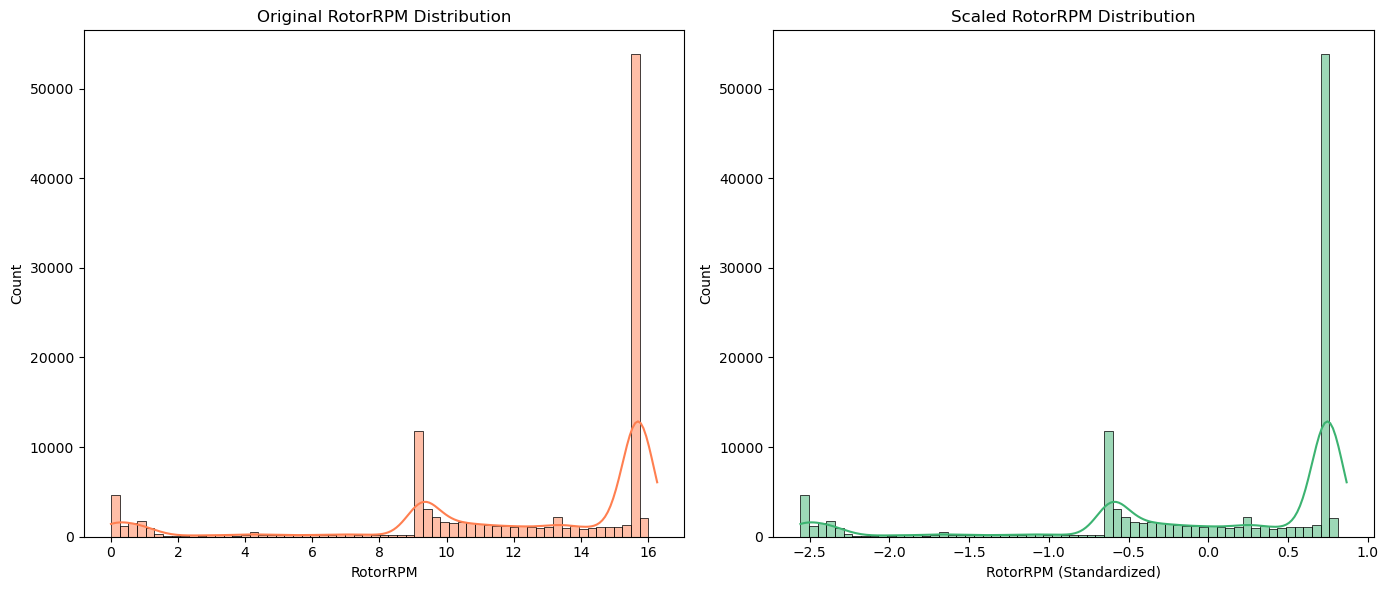

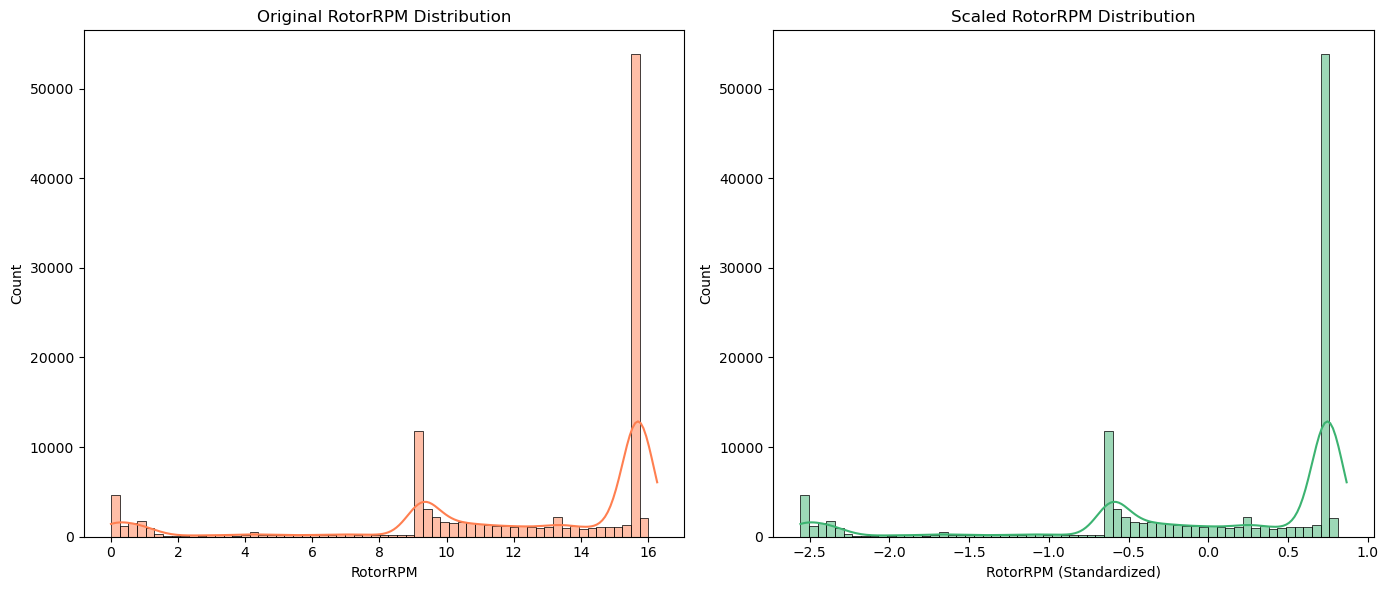

In [15]:
import matplotlib.pyplot as plt
import seaborn as sns

# Visualize scaled vs. original RotorRPM
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Original RotorRPM distribution
sns.histplot(df_imputed['RotorRPM'], ax=axes[0], kde=True, color='coral')
axes[0].set_title('Original RotorRPM Distribution')
axes[0].set_xlabel('RotorRPM')

# Scaled RotorRPM distribution
sns.histplot(scaled_df['RotorRPM'], ax=axes[1], kde=True, color='mediumseagreen')
axes[1].set_title('Scaled RotorRPM Distribution')
axes[1].set_xlabel('RotorRPM (Standardized)')

plt.tight_layout()
plt.show()
import matplotlib.pyplot as plt
import seaborn as sns

# Visualize scaled vs. original RotorRPM
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Original RotorRPM distribution
sns.histplot(df_imputed['RotorRPM'], ax=axes[0], kde=True, color='coral')
axes[0].set_title('Original RotorRPM Distribution')
axes[0].set_xlabel('RotorRPM')

# Scaled RotorRPM distribution
sns.histplot(scaled_df['RotorRPM'], ax=axes[1], kde=True, color='mediumseagreen')
axes[1].set_title('Scaled RotorRPM Distribution')
axes[1].set_xlabel('RotorRPM (Standardized)')

plt.tight_layout()
plt.show()


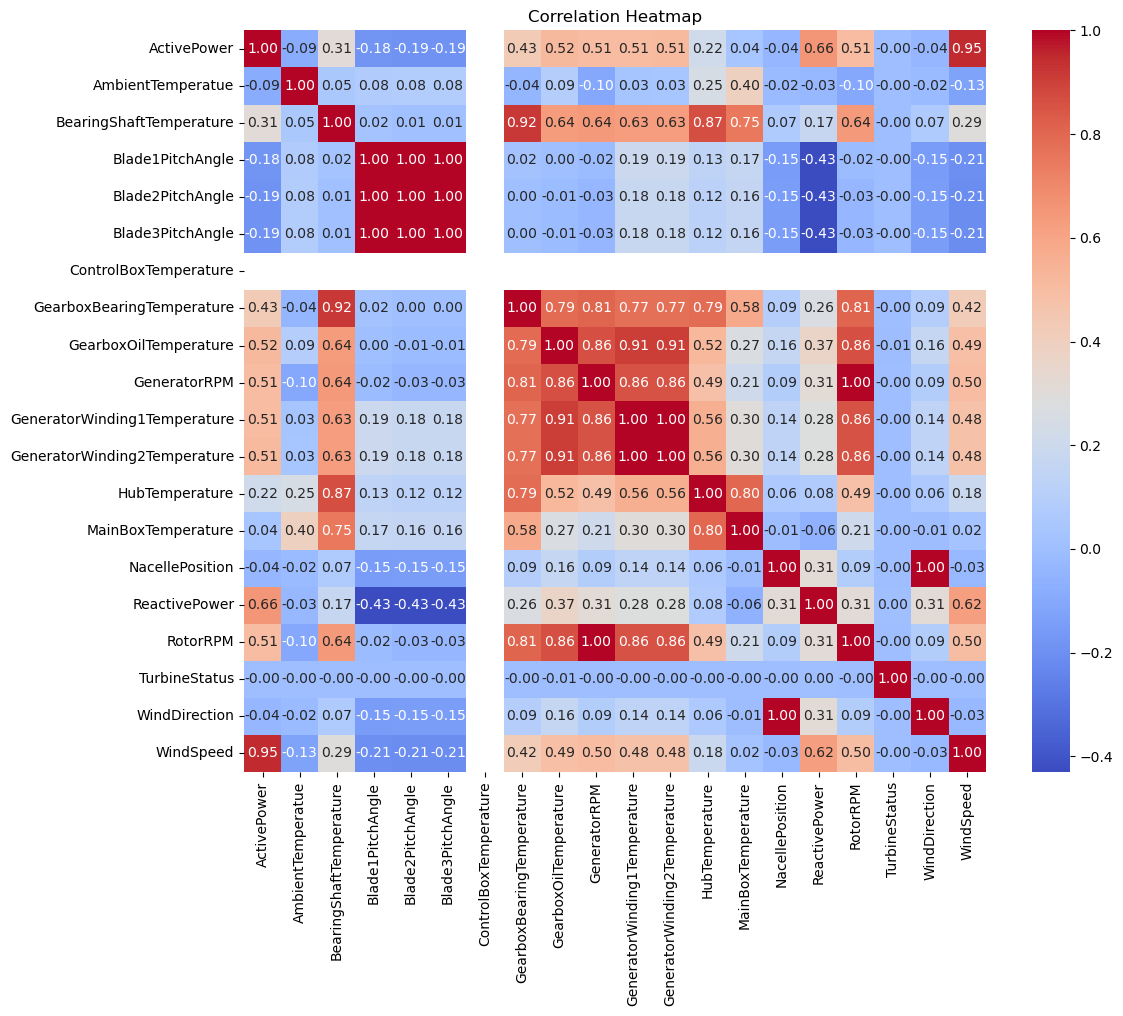

In [17]:
import matplotlib.pyplot as plt
import seaborn as sns

# Drop non-numeric columns like Timestamp
numeric_data = df_imputed.select_dtypes(include=['float64', 'int64'])

# Calculate correlation matrix
correlation_matrix = numeric_data.corr()

# Plot heatmap
plt.figure(figsize=(12, 10))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt='.2f', square=True)
plt.title('Correlation Heatmap')
plt.tight_layout()
plt.show()


In [19]:
# If your cleaned dataset is called df_imputed or df_pca:
numeric_data = df_imputed.select_dtypes(include='number')  # or df_pca if PCA is applied

# Set the correct target column name
target = 'ActivePower'  # Change this if your target column is actually named differently

# Calculate correlations
correlations = numeric_data.corr()[target].abs().sort_values(ascending=False)

# Select top 5 features (excluding the target itself)
top_features = correlations.drop(target).head(5).index.tolist()

print("📊 Selected Features for Modeling:", top_features)


📊 Selected Features for Modeling: ['WindSpeed', 'ReactivePower', 'GearboxOilTemperature', 'GeneratorWinding2Temperature', 'GeneratorWinding1Temperature']


In [23]:
from sklearn.model_selection import train_test_split

# Use the selected top features from Step 6
X = df_imputed[top_features]  # input features
y = df_imputed[target]        # target variable

# Split the data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Show the shapes to confirm
print("Training features shape:", X_train.shape)
print("Test features shape:", X_test.shape)
print("Training labels shape:", y_train.shape)
print("Test labels shape:", y_test.shape)


Training features shape: (93321, 5)
Test features shape: (23331, 5)
Training labels shape: (93321,)
Test labels shape: (23331,)


In [25]:
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.neighbors import KNeighborsRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score, mean_absolute_percentage_error
import pandas as pd

# Define models
models = {
    "Linear Regression": LinearRegression(),
    "Ridge Regression": Ridge(),
    "Lasso Regression": Lasso(),
    "Decision Tree": DecisionTreeRegressor(random_state=42),
    "Gradient Boosting": GradientBoostingRegressor(random_state=42),
    "KNN": KNeighborsRegressor()
}

# Store evaluation results
results = []

for name, model in models.items():
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)

    mae = mean_absolute_error(y_test, y_pred)
    mse = mean_squared_error(y_test, y_pred)
    r2 = r2_score(y_test, y_pred)
    mape = mean_absolute_percentage_error(y_test, y_pred)

    results.append({
        'Model': name,
        'MAE': mae,
        'MSE': mse,
        'R2': r2,
        'MAPE': mape
    })

# Convert to DataFrame
results_df = pd.DataFrame(results)

# Display
print(results_df)


/opt/anaconda3/lib/python3.9/site-packages/sklearn/linear_model/_coordinate_descent.py:697: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 1.060e+09, tolerance: 3.657e+06
  model = cd_fast.enet_coordinate_descent(


               Model         MAE           MSE        R2          MAPE
0  Linear Regression  137.376532  35972.684102  0.907675  1.789201e+16
1   Ridge Regression  137.378751  35972.516086  0.907675  1.789103e+16
2   Lasso Regression  142.162060  36689.078831  0.905836  1.645064e+16
3      Decision Tree   16.578134   3150.496864  0.991914  2.548803e+14
4  Gradient Boosting   31.594726   3708.742687  0.990481  3.371588e+15
5                KNN   16.129863   3052.208269  0.992166  6.002781e+14


/var/folders/_y/r_y25lcd4ysdnk8f0xjyzm0h0000gn/T/ipykernel_1614/1404019086.py:31: UserWarning: Glyph 128202 (\N{BAR CHART}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/opt/anaconda3/lib/python3.9/site-packages/IPython/core/pylabtools.py:152: UserWarning: Glyph 128202 (\N{BAR CHART}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


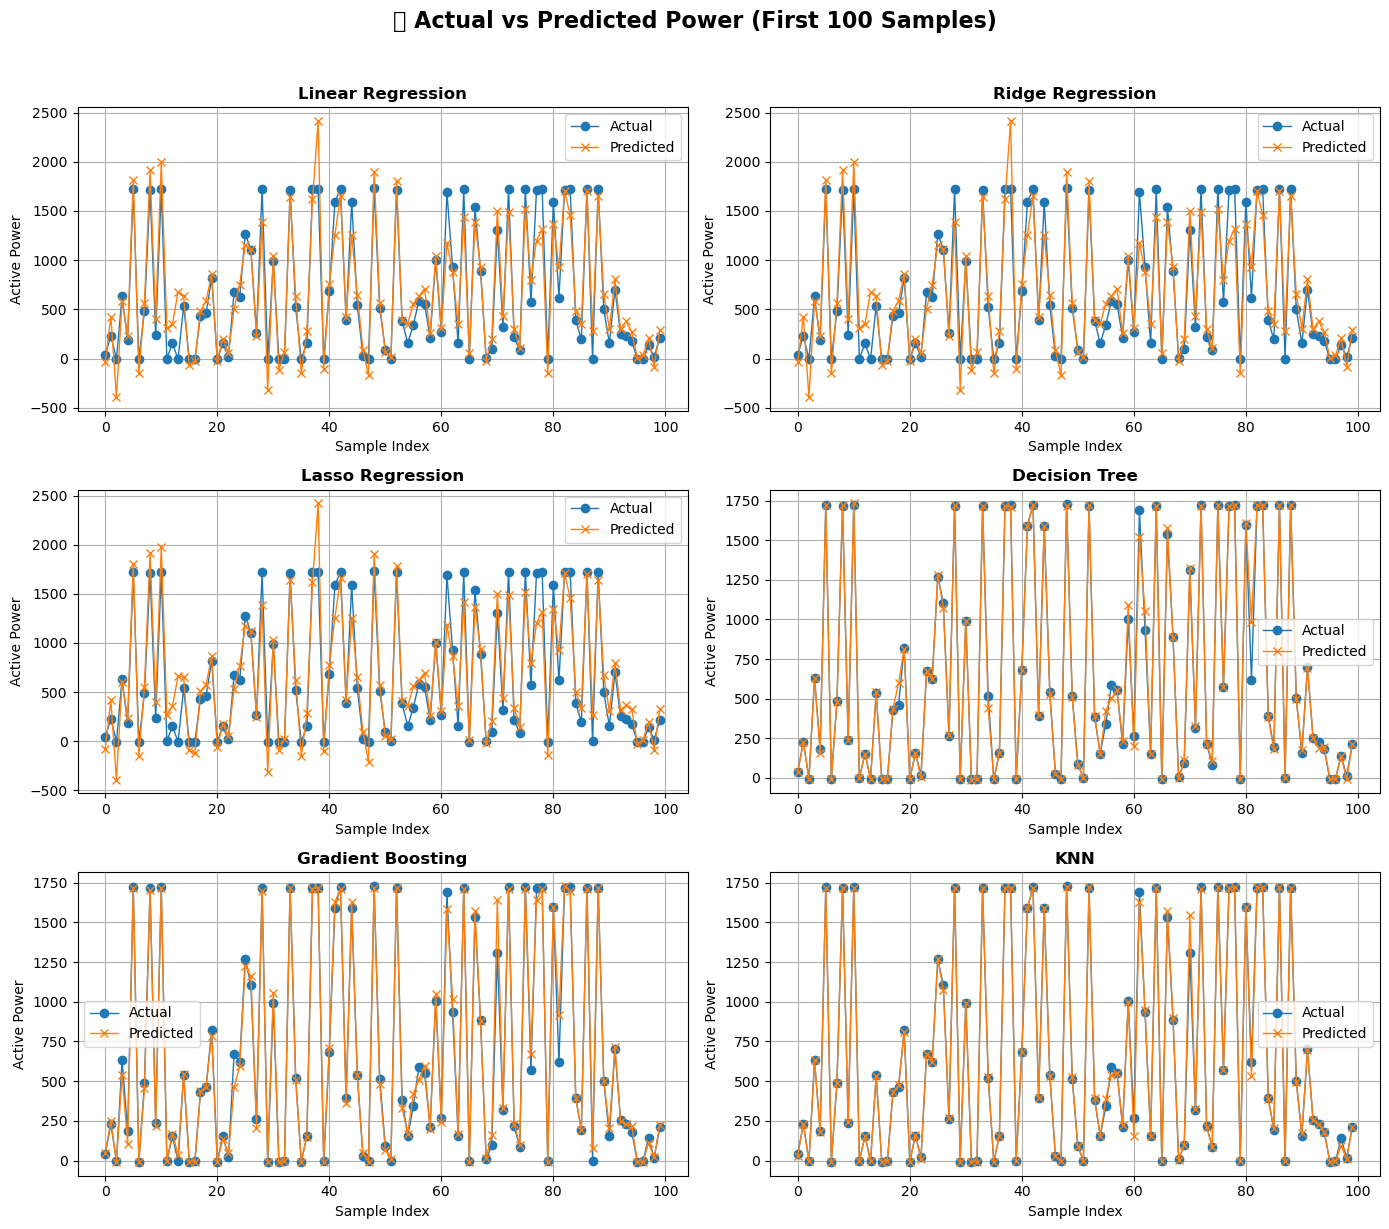

In [27]:
import matplotlib.pyplot as plt
import math

# Number of samples to visualize
sample_range = 100

# Total models
n_models = len(models)
cols = 2
rows = math.ceil(n_models / cols)

# Create figure
plt.figure(figsize=(14, rows * 4))

# Loop through models and plot
for i, (name, model) in enumerate(models.items(), start=1):
    preds = model.predict(X_test)

    plt.subplot(rows, cols, i)
    plt.plot(y_test.values[:sample_range], label='Actual', marker='o', linewidth=1)
    plt.plot(preds[:sample_range], label='Predicted', marker='x', linewidth=1)
    
    plt.title(f"{name}", fontsize=12, weight='bold')
    plt.xlabel("Sample Index")
    plt.ylabel("Active Power")
    plt.legend()
    plt.grid(True)

# Adjust layout
plt.suptitle("📊 Actual vs Predicted Power (First 100 Samples)", fontsize=16, weight='bold', y=1.02)
plt.tight_layout()
plt.show()


In [29]:
# Find the correct R² column key, in case it's not exactly 'R²'
r2_key = next((col for col in results_df.columns if 'r2' in col.lower()), None)

if r2_key:
    best_by_mae = results_df.loc[results_df['MAE'].idxmin()]
    best_by_mse = results_df.loc[results_df['MSE'].idxmin()]
    best_by_r2 = results_df.loc[results_df[r2_key].idxmax()]
    best_by_mape = results_df.loc[results_df['MAPE'].idxmin()]

    print("✅ Best Model by MAE:", best_by_mae['Model'])
    print("✅ Best Model by MSE:", best_by_mse['Model'])
    print(f"✅ Best Model by {r2_key}:", best_by_r2['Model'])
    print("✅ Best Model by MAPE:", best_by_mape['Model'])
else:
    print("❌ 'R²' or similar column not found in the results.")


✅ Best Model by MAE: KNN
✅ Best Model by MSE: KNN
✅ Best Model by R2: KNN
✅ Best Model by MAPE: Decision Tree


/var/folders/_y/r_y25lcd4ysdnk8f0xjyzm0h0000gn/T/ipykernel_1614/2724873638.py:16: UserWarning: Glyph 128269 (\N{LEFT-POINTING MAGNIFYING GLASS}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/opt/anaconda3/lib/python3.9/site-packages/IPython/core/pylabtools.py:152: UserWarning: Glyph 128269 (\N{LEFT-POINTING MAGNIFYING GLASS}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


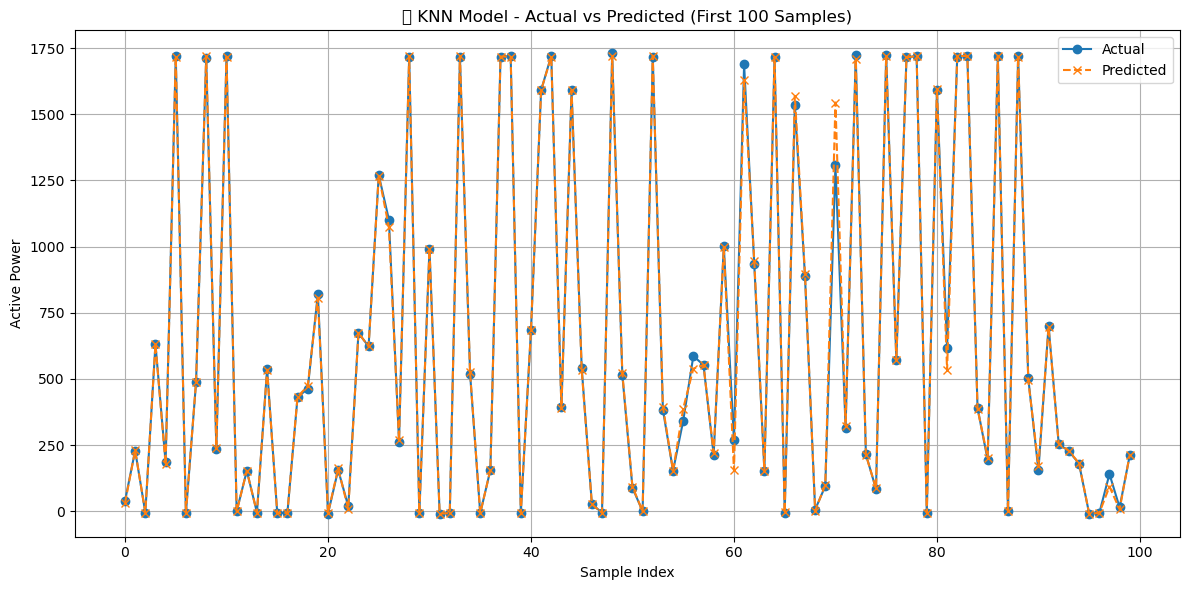

In [31]:
import matplotlib.pyplot as plt

# Predict using the trained KNN model
best_model = models['KNN']  # Make sure 'KNN' is the exact key
y_pred_knn = best_model.predict(X_test)

# Plot actual vs predicted values
plt.figure(figsize=(12, 6))
plt.plot(y_test.values[:100], label='Actual', marker='o', linestyle='-')
plt.plot(y_pred_knn[:100], label='Predicted', marker='x', linestyle='--')
plt.title("🔍 KNN Model - Actual vs Predicted (First 100 Samples)")
plt.xlabel("Sample Index")
plt.ylabel("Active Power")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


In [33]:
from sklearn.neighbors import KNeighborsRegressor
import joblib

best_model = KNeighborsRegressor()
best_model.fit(X_train, y_train)

joblib.dump(best_model, "best_knn_model.pkl")
print("✅ KNN model saved as 'best_knn_model.pkl'")


✅ KNN model saved as 'best_knn_model.pkl'


In [6]:
results_df.to_csv("model_comparison_report.csv", index=False)
print("✅ Report saved as model_comparison_report.csv")


✅ Report saved as model_comparison_report.csv
